John S. Anvik, 2025  
University of Lethbridge Student ID: 001224816

In [7]:
library(tidyverse)
data <- read_csv("../data/megazord.csv")

New names:
• `` -> `...1`
Warning message:
“One or more parsing issues, call `problems()` on your data frame for details,
e.g.:
  dat <- vroom(...)
  problems(dat)”
Rows: 12799 Columns: 127
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (14): ID, recordist, Begin.Path, Location_Number, Comments, ST1, Data_...
dbl  (104): ...1, X.2, X.1, selec, start, end, File.Offset..s., SNR.NIST.Qui...
lgl    (2): RepeatST, GreaterThanT
dttm   (1): DateTime
date   (1): date
time   (5): click_clock, start_hms, click_clock_hms, clock_time, sunrise

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [10]:
data %>% select(ID, DateTime, date, time_rel_sunrise, UST, IST, neighbourhood, Lat, Lon)

ID,DateTime,date,time_rel_sunrise,UST,IST,neighbourhood,Lat,Lon
<chr>,<dttm>,<date>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>
DgTbO,2022-05-13 05:11:40,2022-05-13,-2690.000,NA,NA,north,NA,NA
DgTbO,2022-05-13 05:24:14,2022-05-13,-1935.691,25,DgTbO_13,north,17.98047,-67.16493
DgTbO,2022-05-13 05:24:40,2022-05-13,-1909.821,20,DgTbO_1,north,17.98047,-67.16493
DgTbO,2022-05-13 05:24:48,2022-05-13,-1901.666,1,DgTbO_6,north,17.98047,-67.16493
DgTbO,2022-05-13 05:24:59,2022-05-13,-1890.748,153,DgTbO_4,north,17.98047,-67.16493
DgTbO,2022-05-13 05:25:09,2022-05-13,-1880.963,33,DgTbO_5,north,17.98047,-67.16493
DgTbO,2022-05-13 05:25:18,2022-05-13,-1871.335,8,DgTbO_7,north,17.98047,-67.16493
DgTbO,2022-05-13 05:25:26,2022-05-13,-1863.036,33,DgTbO_5,north,17.98047,-67.16493
DgTbO,2022-05-13 05:25:35,2022-05-13,-1854.549,20,DgTbO_1,north,17.98047,-67.16493


In [3]:
northdata <- data %>% filter(neighbourhood == "north")
centredata <- data %>% filter(neighbourhood == "centre")
# southdata <- data %>% filter(neighbourhood == "south") # Ignoring south neighbourhood for now due to lack of good data

Warning message:
"Removed 155 rows containing non-finite outside the scale range
(`stat_count()`)."


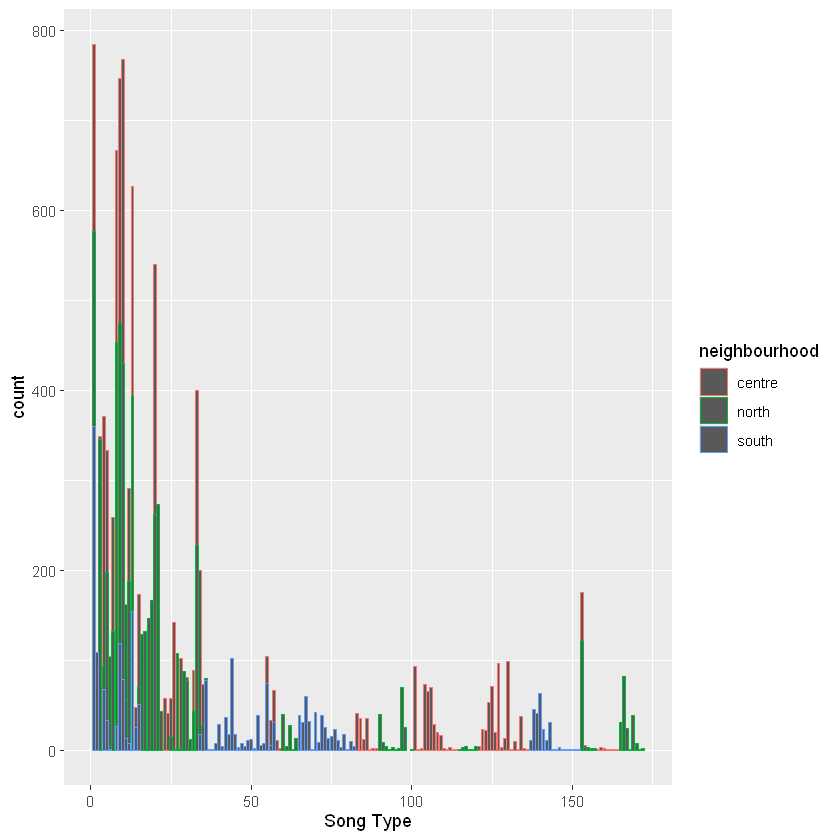

In [4]:
print(
    ggplot() +
    geom_bar(data=data, aes(UST, color=neighbourhood)) +
    xlab("Song Type")
)

Warning message:
"Removed 48 rows containing non-finite outside the scale range (`stat_count()`)."
Warning message:
"Removed 65 rows containing non-finite outside the scale range (`stat_count()`)."


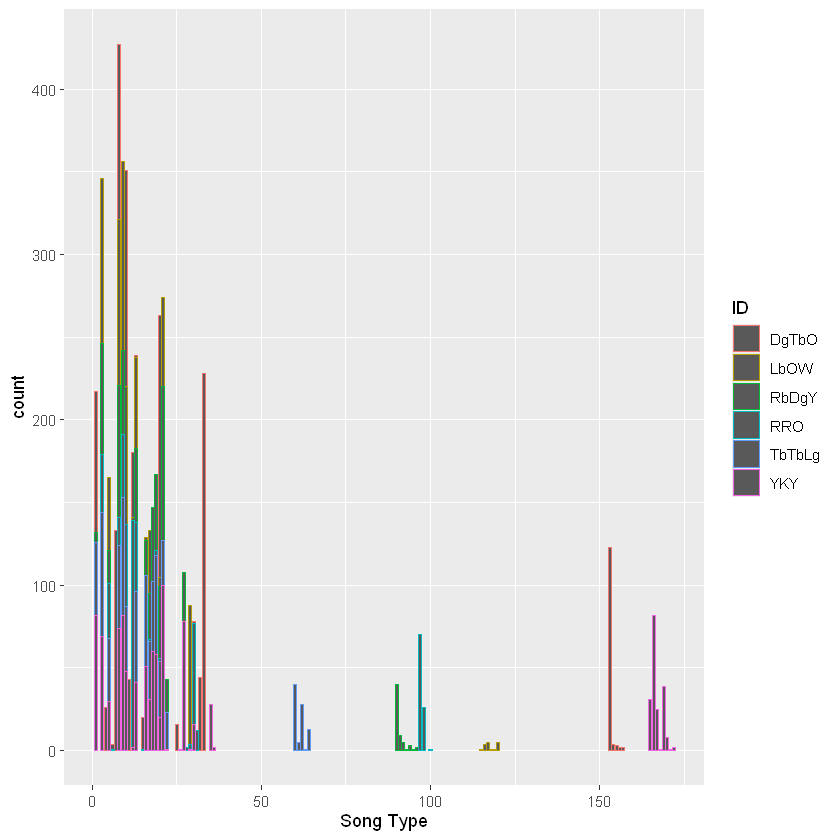

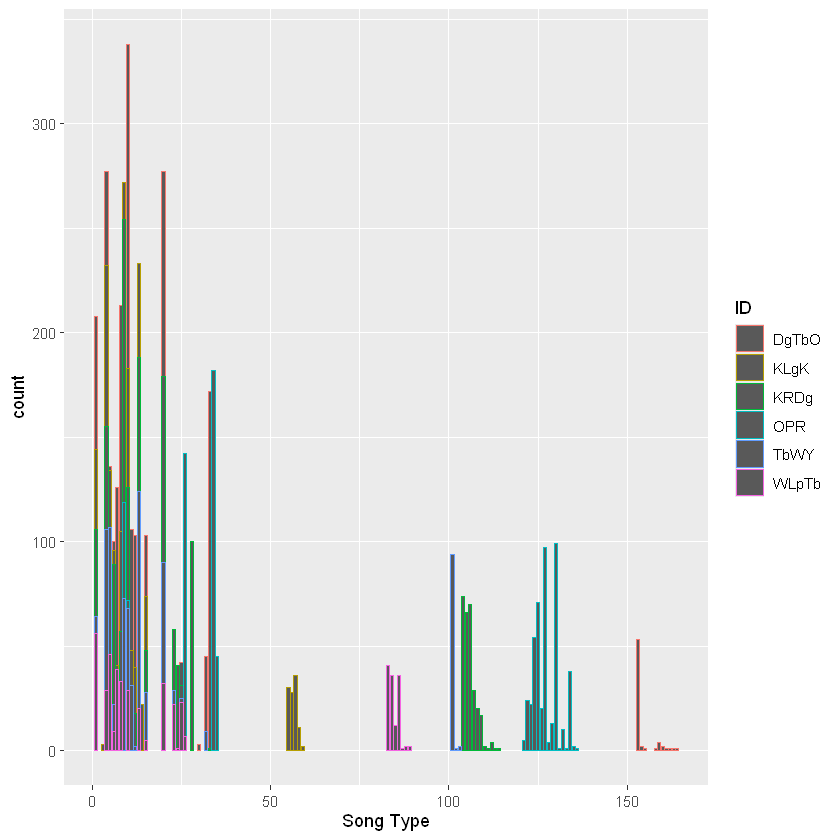

In [5]:
# North neighbourhood
print(
    ggplot() +
    geom_bar(data=northdata, aes(UST, color=ID)) +
    xlab("Song Type")
)

# Centre neighbourhood
print(
    ggplot() +
    geom_bar(data=centredata, aes(UST, color=ID)) +
    xlab("Song Type")
)

Warning message:
"Removed 155 rows containing missing values or values outside the scale range
(`geom_point()`)."


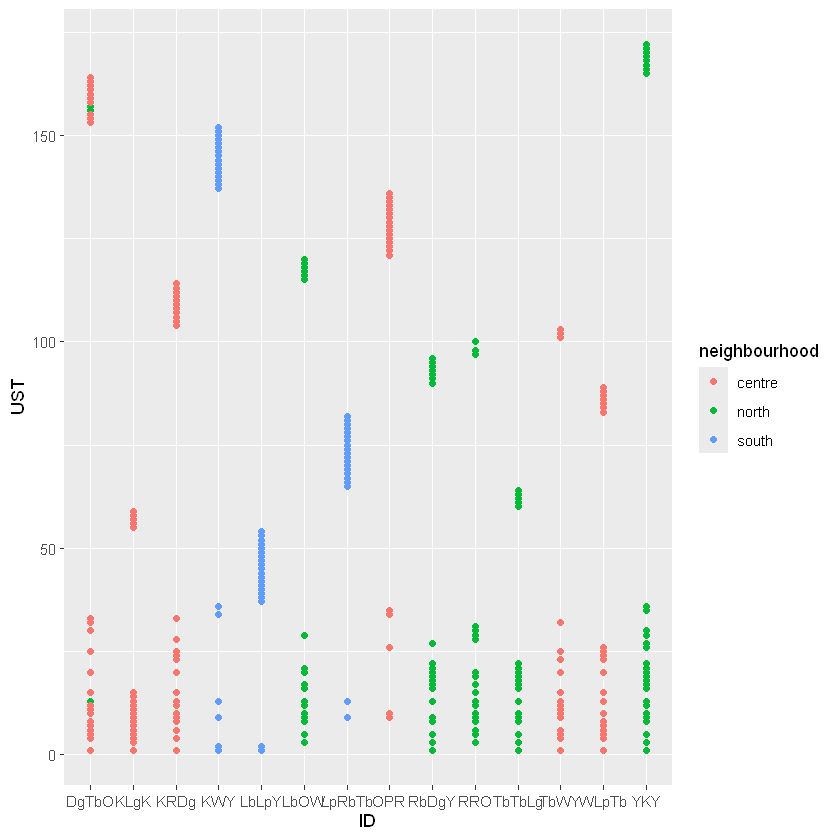

In [6]:
ggplot() + geom_point(data=data, aes(y=UST, x=ID, color = neighbourhood))

Warning message:
"Removed 155 rows containing missing values or values outside the scale range
(`geom_point()`)."


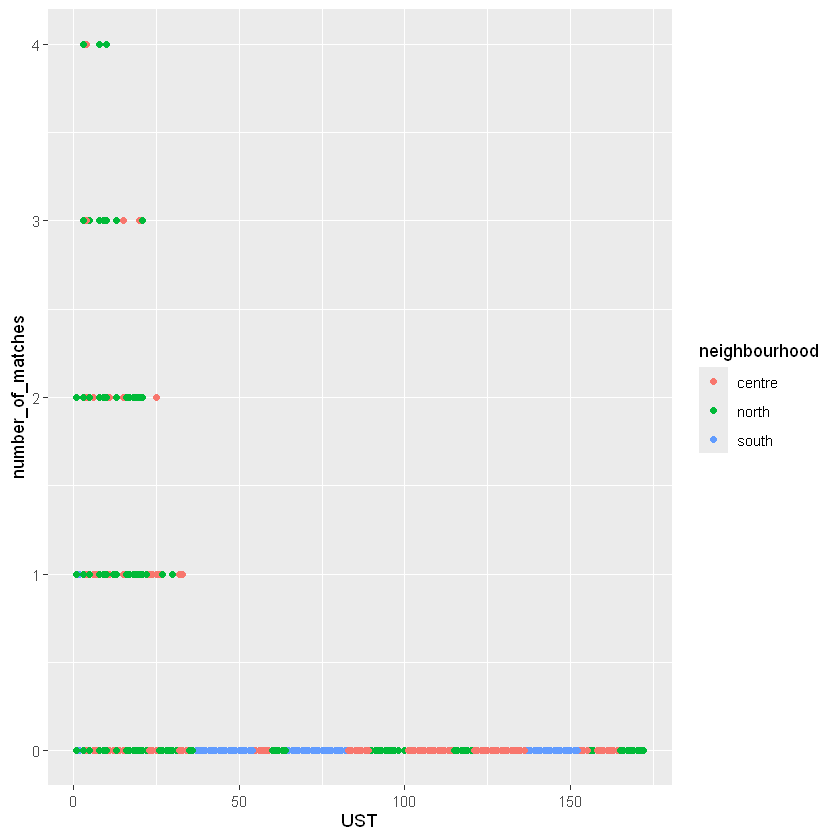

In [11]:
# Do certain song types have more matches?
ggplot() + 
    geom_point(data=data, aes(x=UST, y=number_of_matches, color=neighbourhood))

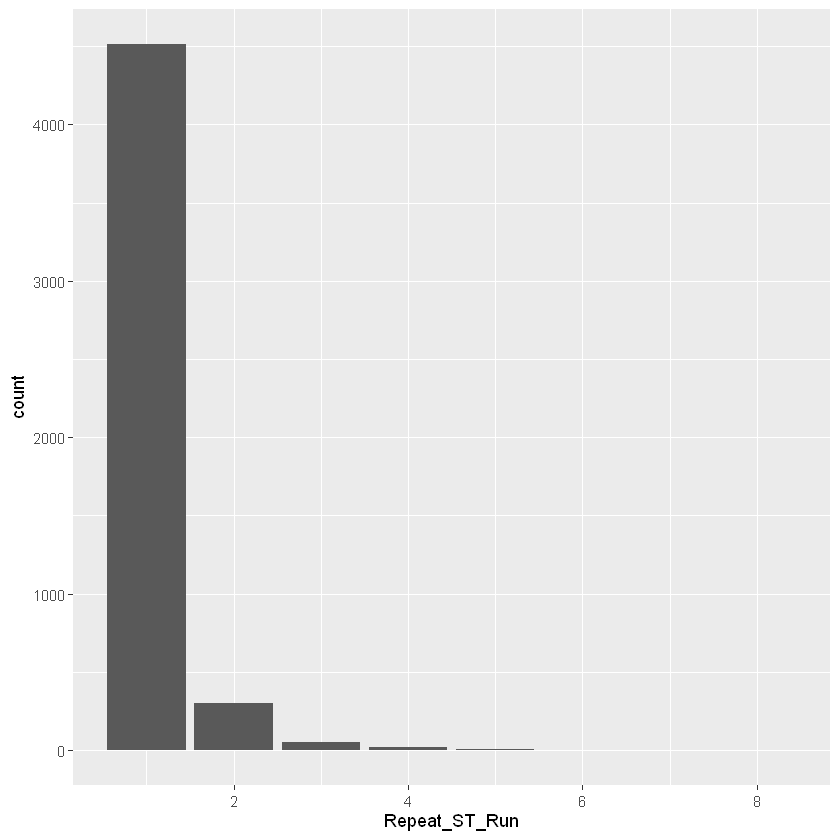

In [ ]:
# How many times were song types repeated?
# One is the most common value by far, suggesting song types are very rarely repeated
# Two is very rare, it appears the maximum is eight
ggplot() +
    geom_bar(data=northdata, aes(x=Repeat_ST_Run))